# Resolve the smaller singular value
Run with OneSimulation, NumPy and Matplotlib installed.
Change the separation grid. Which lost singular value can a direct SVD still measure?

At delta=1e-12: direct/reference=1.000, Gram/reference=0.000


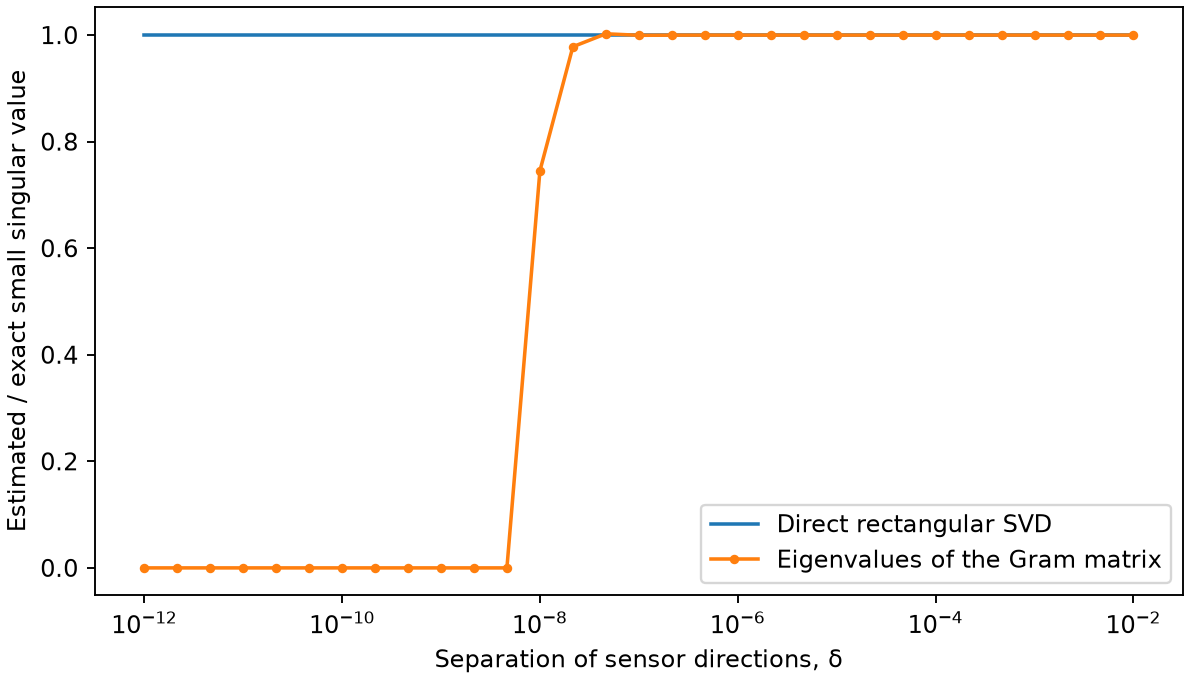

In [1]:
"""Measure loss of the weaker of two almost parallel sensor directions."""
import matplotlib.pyplot as plt
import numpy as np
from onesim.numerics.linear.matrices.dense_linear_algebra import symmetric_eigenvalues

separations = np.logspace(-12, -2, 31)
direct, normal = [], []
for delta in separations:
    matrix = np.array([[1.0, 1.0], [delta, -delta], [0.0, 0.0]])
    reference = np.sqrt(2.0) * delta
    direct.append(np.linalg.svd(matrix, compute_uv=False)[-1] / reference)
    smallest = symmetric_eigenvalues(matrix.T @ matrix)[0]
    normal.append(np.sqrt(max(smallest, 0.0)) / reference)

assert np.allclose(direct, 1.0)
assert normal[0] == 0.0
print(f"At delta={separations[0]:.0e}: direct/reference={direct[0]:.3f}, Gram/reference={normal[0]:.3f}")
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.semilogx(separations, direct, label="Direct rectangular SVD")
ax.semilogx(separations, normal, "o-", ms=3, label="Eigenvalues of the Gram matrix")
ax.set(xlabel="Separation of sensor directions, δ", ylabel="Estimated / exact small singular value")
ax.legend()
fig.savefig("numerics-small-singular-value.png", dpi=170)
